# Phase 1 Baseline Models: Leakage-Safe Chronological Evaluation

**Project:** Rainfall-Lag-Aware Crop Yield Forecasting in India Using Explainable Temporal Machine Learning

**Objective:**
Train and evaluate `RandomForestRegressor` and `XGBRegressor` on a strict chronological temporal split (Train: 1990–2009, Validation: 2010–2013, Test: 2014–2017).

**Scientific Protocol:**
- Zero temporal leakage: future observations never enter training or hyperparameter tuning.
- Categorical one-hot encoder is fitted strictly on the training partition.
- Test set is completely held out until final evaluation.

In [1]:
import sys
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd()))

from src.config import load_config
from src.splitting import compute_temporal_splits
from src.models import BaselinePipeline, train_random_forest, train_xgboost, build_prediction_dataframe
from src.evaluation import evaluate_splits, compute_group_metrics
from src.visualization import (
    plot_actual_vs_predicted,
    plot_residual_distribution,
    plot_state_mae,
    plot_district_mae_distribution,
)

config = load_config()
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Load Clean Dataset and Apply Chronological Split
Enforcing $Train < Val < Test$ chronological boundaries.

In [2]:
clean_df = pd.read_csv('data/processed/phase1_clean.csv')

train_df, val_df, test_df, split_summary = compute_temporal_splits(
    clean_df,
    custom_year_bounds={
        'train_years': config['split']['train_years'],
        'val_years': config['split']['val_years'],
        'test_years': config['split']['test_years'],
    }
)

split_summary.to_csv('results/tables/temporal_split_summary.csv', index=False)
print(f'Train: {len(train_df)} rows ({train_df["Year"].min()}–{train_df["Year"].max()})')
print(f'Val:   {len(val_df)} rows ({val_df["Year"].min()}–{val_df["Year"].max()})')
print(f'Test:  {len(test_df)} rows ({test_df["Year"].min()}–{test_df["Year"].max()})')
split_summary

Train: 7361 rows (1990–2009)
Val:   1448 rows (2010–2013)
Test:  1470 rows (2014–2017)


,split,start_year,end_year,n_rows,n_states,n_districts
0,train,1990,2009,7361,20,383
1,validation,2010,2013,1448,20,367
2,test,2014,2017,1470,20,379


## 2. Feature Preparation & Leakage-Free Encoding
Fit OneHotEncoder strictly on `train_df`, and transform `val_df` and `test_df`.

In [3]:
pipeline = BaselinePipeline(
    num_features=['IMD_RF', 'IMD_Tmax', 'SD_RF_jun_nov'],
    cat_features=['State_Clean'],
)

X_train = pipeline.fit_transform(train_df)
y_train = train_df['RICE.YIELD..Kg.per.ha.'].values

X_val = pipeline.transform(val_df)
y_val = val_df['RICE.YIELD..Kg.per.ha.'].values

X_test = pipeline.transform(test_df)
y_test = test_df['RICE.YIELD..Kg.per.ha.'].values

print(f'Feature dimension: {X_train.shape[1]} columns')
print(f'Feature names: {pipeline.feature_names}')

Feature dimension: 23 columns
Feature names: ['IMD_RF', 'IMD_Tmax', 'SD_RF_jun_nov', 'State_Clean_Andhra Pradesh', 'State_Clean_Assam', 'State_Clean_Bihar', 'State_Clean_Chhattisgarh', 'State_Clean_Gujarat', 'State_Clean_Haryana', 'State_Clean_Himachal Pradesh', 'State_Clean_Jharkhand', 'State_Clean_Karnataka', 'State_Clean_Kerala', 'State_Clean_Madhya Pradesh', 'State_Clean_Maharashtra', 'State_Clean_Odisha', 'State_Clean_Punjab', 'State_Clean_Rajasthan', 'State_Clean_Tamil Nadu', 'State_Clean_Telangana', 'State_Clean_Uttar Pradesh', 'State_Clean_Uttarakhand', 'State_Clean_West Bengal']


## 3. Train & Tune Random Forest Regressor
Validation-based hyperparameter tuning; save model to `results/models/random_forest.joblib`.

In [4]:
rf_model, rf_params = train_random_forest(
    X_train, y_train, X_val, y_val, params=config['models']['random_forest']
)
joblib.dump(rf_model, 'results/models/random_forest.joblib')
print(f'Random Forest trained with tuned params: {rf_params}')

# Generate predictions
rf_train_preds = rf_model.predict(X_train)
rf_val_preds = rf_model.predict(X_val)
rf_test_preds = rf_model.predict(X_test)

rf_test_pred_df = build_prediction_dataframe(test_df, rf_test_preds)
rf_test_pred_df.to_csv('results/predictions/random_forest_test_predictions.csv', index=False)
print('RF test predictions saved. Sample:')
rf_test_pred_df.head(5)

Random Forest trained with tuned params: {'n_estimators': 200, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'random_state': 42, 'n_jobs': -1}


RF test predictions saved. Sample:


,stable_geographic_id,State,District,Year,Actual,Predicted,Residual
0,CHHATTISGARH_1,Chhattisgarh,Durg,2014,1820.000000,1221.78,598.22
1,CHHATTISGARH_1,Chhattisgarh,Durg,2015,1288.666667,1210.52,78.15
2,CHHATTISGARH_1,Chhattisgarh,Durg,2016,2383.000000,1206.16,1176.84
3,CHHATTISGARH_1,Chhattisgarh,Durg,2017,1267.000000,1191.84,75.16
4,CHHATTISGARH_2,Chhattisgarh,Bastar,2014,2021.857143,1279.71,742.15


## 4. Train & Tune XGBoost Regressor
Validation-based hyperparameter selection; save model to `results/models/xgboost.joblib`.

In [5]:
xgb_model, xgb_params = train_xgboost(
    X_train, y_train, X_val, y_val, params=config['models']['xgboost']
)
joblib.dump(xgb_model, 'results/models/xgboost.joblib')
print(f'XGBoost trained with tuned params: {xgb_params}')

# Generate predictions
xgb_train_preds = xgb_model.predict(X_train)
xgb_val_preds = xgb_model.predict(X_val)
xgb_test_preds = xgb_model.predict(X_test)

xgb_test_pred_df = build_prediction_dataframe(test_df, xgb_test_preds)
xgb_test_pred_df.to_csv('results/predictions/xgboost_test_predictions.csv', index=False)
print('XGBoost test predictions saved. Sample:')
xgb_test_pred_df.head(5)

XGBoost trained with tuned params: {'n_estimators': 250, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'random_state': 42, 'n_jobs': -1}
XGBoost test predictions saved. Sample:


,stable_geographic_id,State,District,Year,Actual,Predicted,Residual
0,CHHATTISGARH_1,Chhattisgarh,Durg,2014,1820.000000,1143.239990,676.76
1,CHHATTISGARH_1,Chhattisgarh,Durg,2015,1288.666667,1153.849976,134.82
2,CHHATTISGARH_1,Chhattisgarh,Durg,2016,2383.000000,1156.410034,1226.59
3,CHHATTISGARH_1,Chhattisgarh,Durg,2017,1267.000000,1145.319946,121.68
4,CHHATTISGARH_2,Chhattisgarh,Bastar,2014,2021.857143,1202.119995,819.74


## 5. Consolidated Model Evaluation Metrics
Compute MAE, RMSE, and R² across Train, Validation, and Test splits.

In [6]:
rf_records = evaluate_splits('Random Forest', y_train, rf_train_preds, y_val, rf_val_preds, y_test, rf_test_preds)
xgb_records = evaluate_splits('XGBoost', y_train, xgb_train_preds, y_val, xgb_val_preds, y_test, xgb_test_preds)

metrics_df = pd.DataFrame(rf_records + xgb_records)
metrics_df.to_csv('results/tables/phase1_metrics.csv', index=False)
metrics_df

,model,split,MAE,RMSE,R2,n_samples
0,Random Forest,train,276.574,370.373,0.8351,7361
1,Random Forest,validation,606.299,774.581,0.3386,1448
2,Random Forest,test,727.194,914.197,0.1333,1470
3,XGBoost,train,311.077,415.272,0.7926,7361
4,XGBoost,validation,601.744,772.979,0.3414,1448
5,XGBoost,test,732.229,921.292,0.1198,1470


## 6. Disaggregated Error Analysis: State & District Levels
Compute spatial performance metrics across Indian states and districts on the test set.

In [7]:
state_metrics = compute_group_metrics(xgb_test_pred_df, group_cols=['State'], min_samples=3)
state_metrics.to_csv('results/tables/state_test_metrics.csv', index=False)

district_metrics = compute_group_metrics(xgb_test_pred_df, group_cols=['stable_geographic_id', 'State', 'District'], min_samples=3)
district_metrics.to_csv('results/tables/district_test_metrics.csv', index=False)

print(f'Evaluated {len(state_metrics)} states and {len(district_metrics)} districts on test partition.')
state_metrics.head(10)

Evaluated 20 states and 360 districts on test partition.


,State,n_samples,MAE,RMSE,R2
0,Himachal Pradesh,44,389.535,493.101,0.0545
1,Uttarakhand,36,418.342,601.868,-0.0514
2,Chhattisgarh,28,485.487,622.327,-1.0057
3,Uttar Pradesh,216,492.040,583.488,-0.5162
4,Kerala,56,492.288,593.181,-0.6716
5,Haryana,60,534.932,642.003,-0.0534
6,Assam,92,597.434,687.680,-4.0230
7,Gujarat,56,613.301,720.145,-0.3033
8,Telangana,36,620.269,736.442,-1.6362
9,West Bengal,60,625.608,730.660,-1.1952


## 7. Model Diagnostic Visualizations
Generate actual vs predicted, residual distribution, and spatial MAE plots.

C:\Users\sanka\OneDrive\Desktop\SE DA\src\visualization.py:234: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sorted_df, x="MAE", y="State", ax=ax, palette="rocket")


Evaluation plots saved.


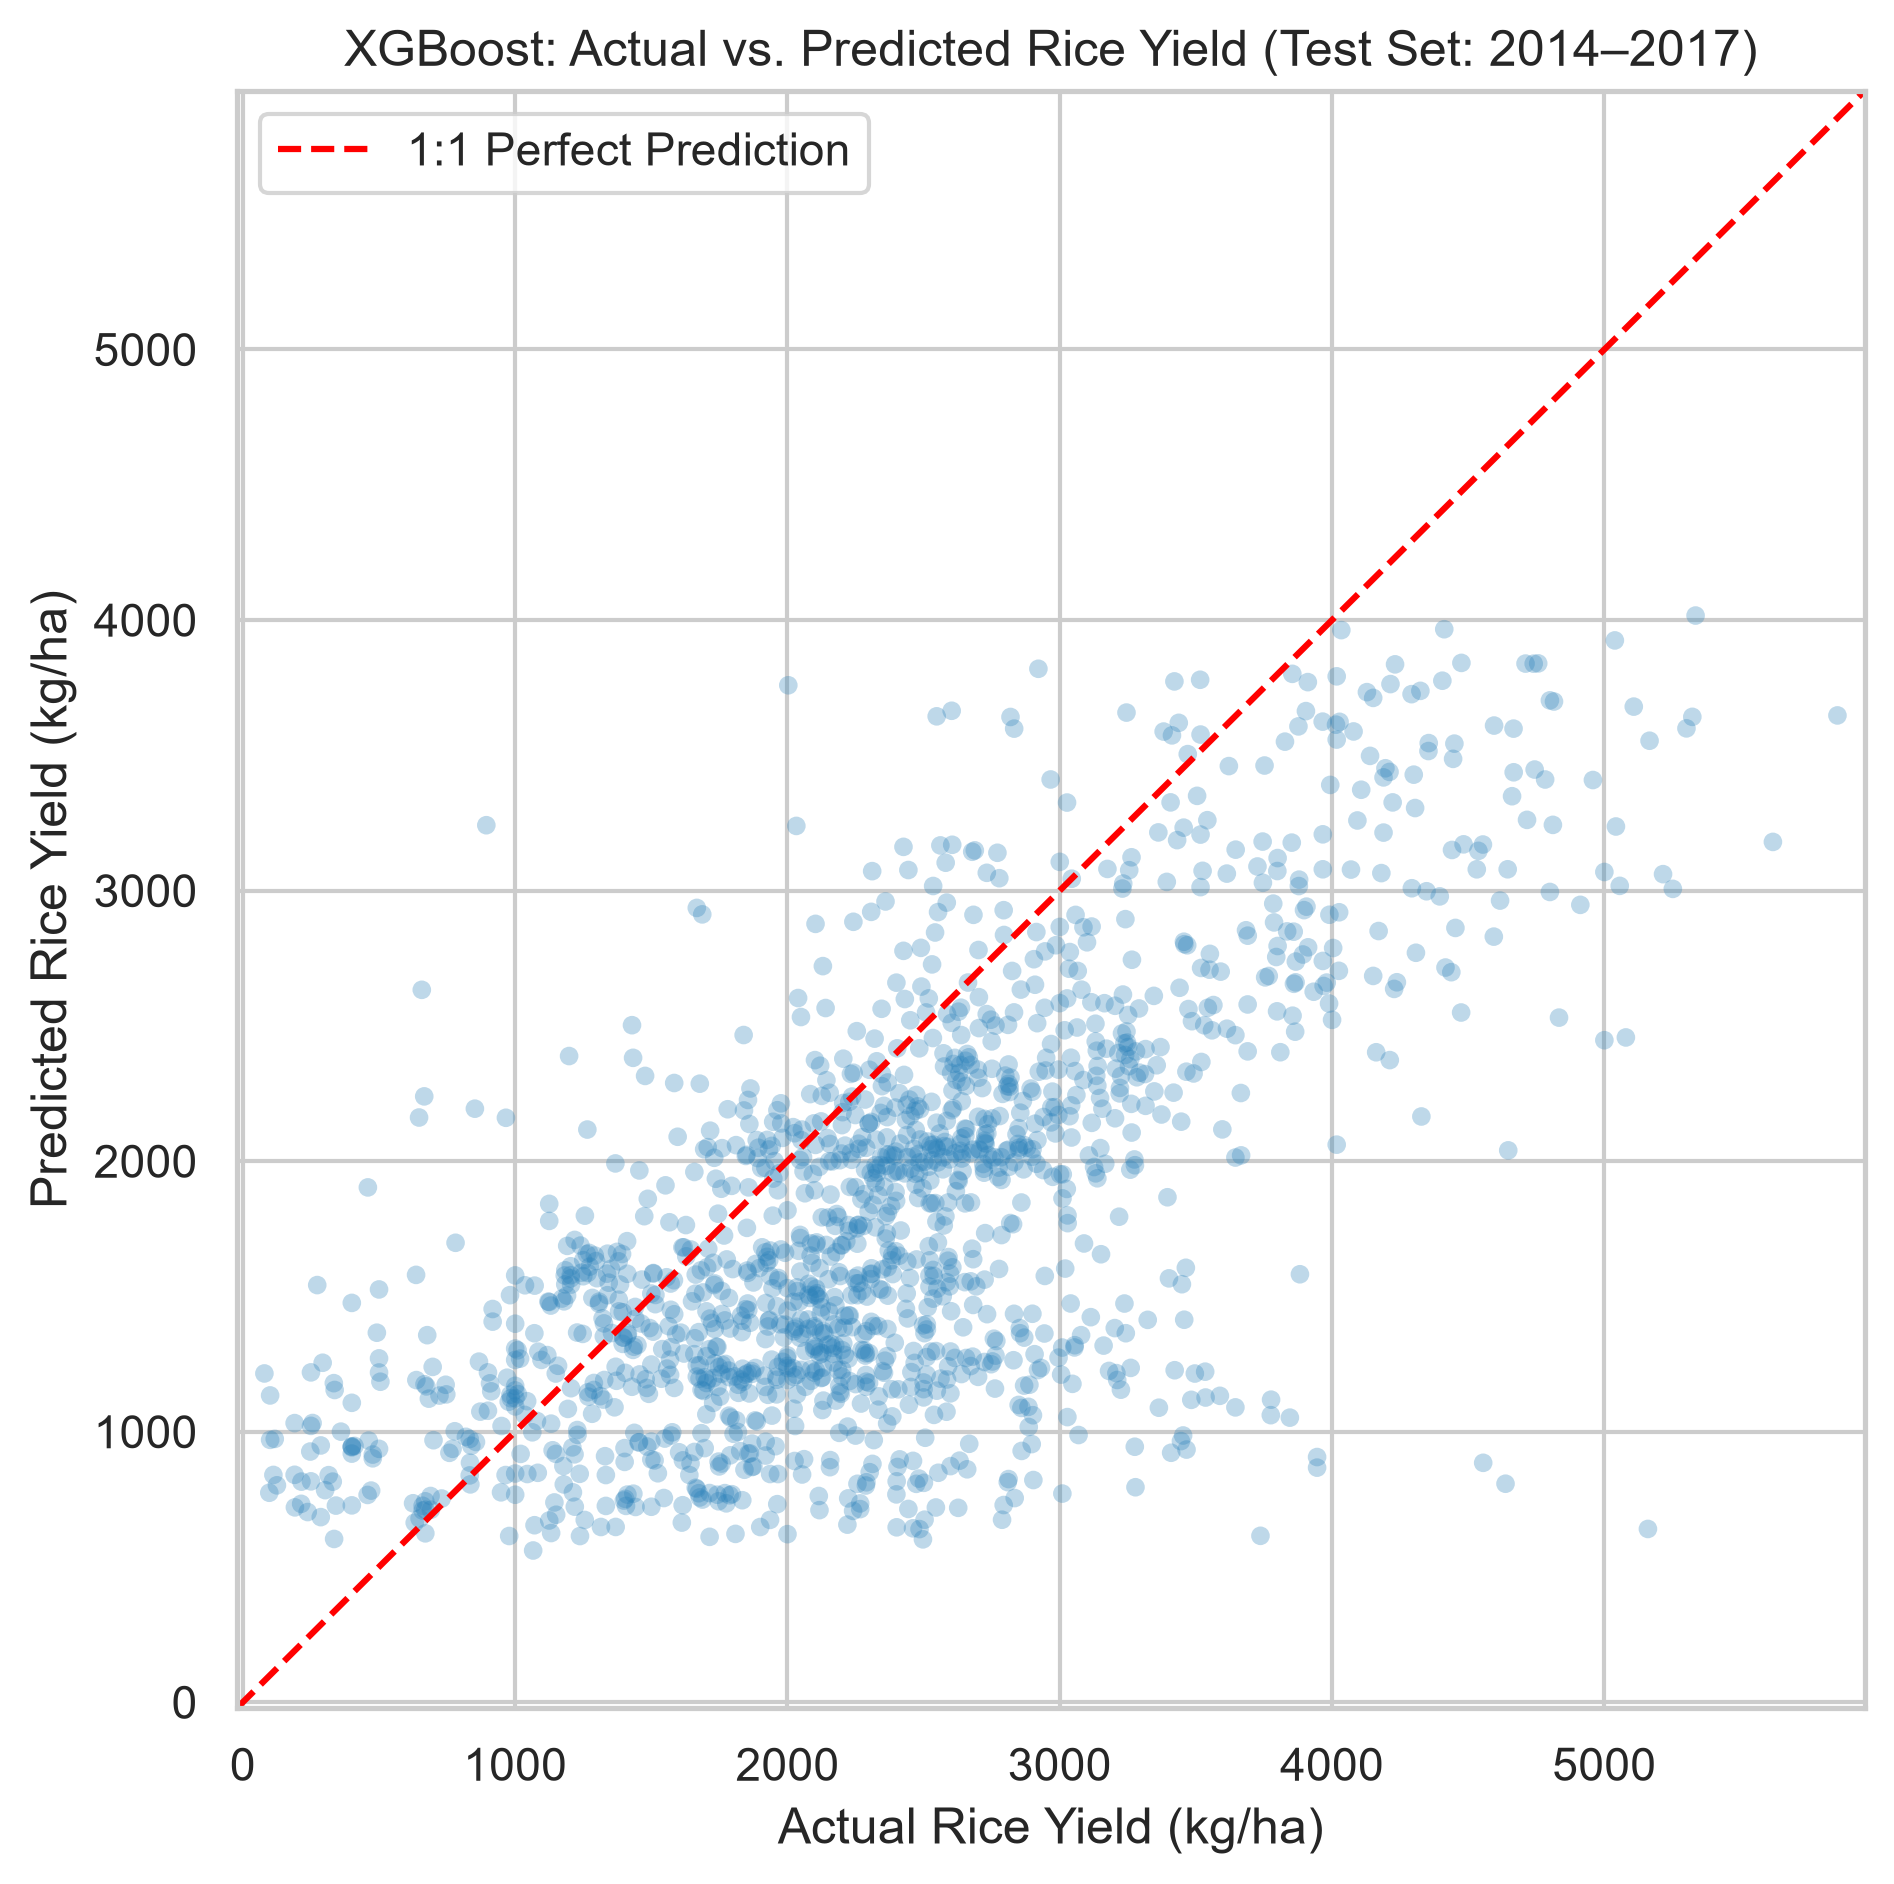

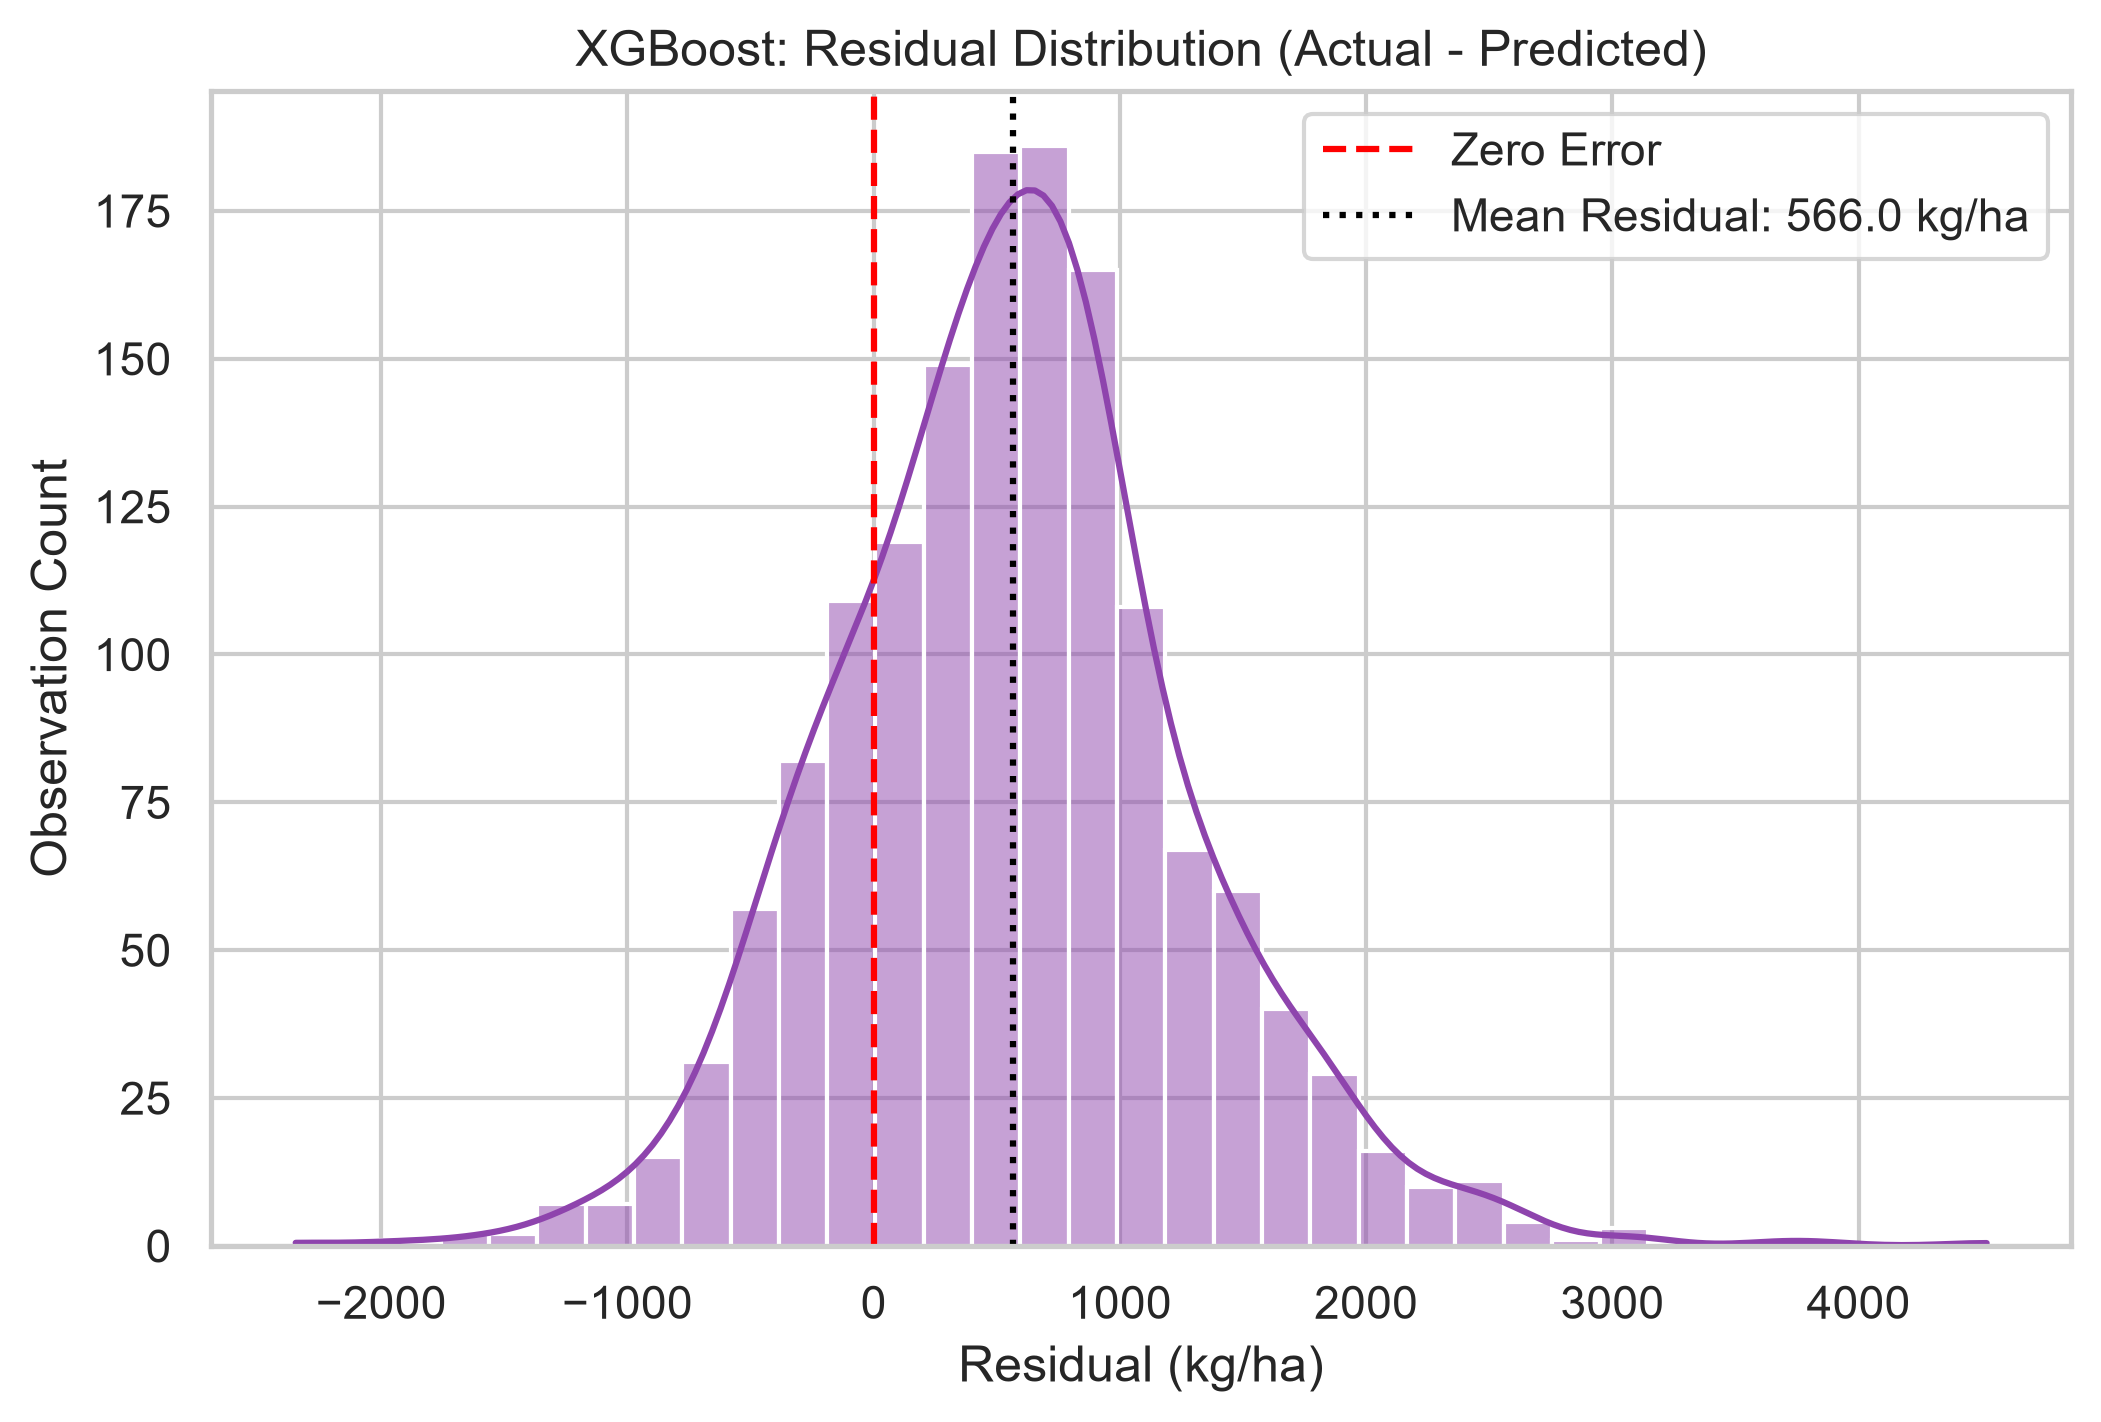

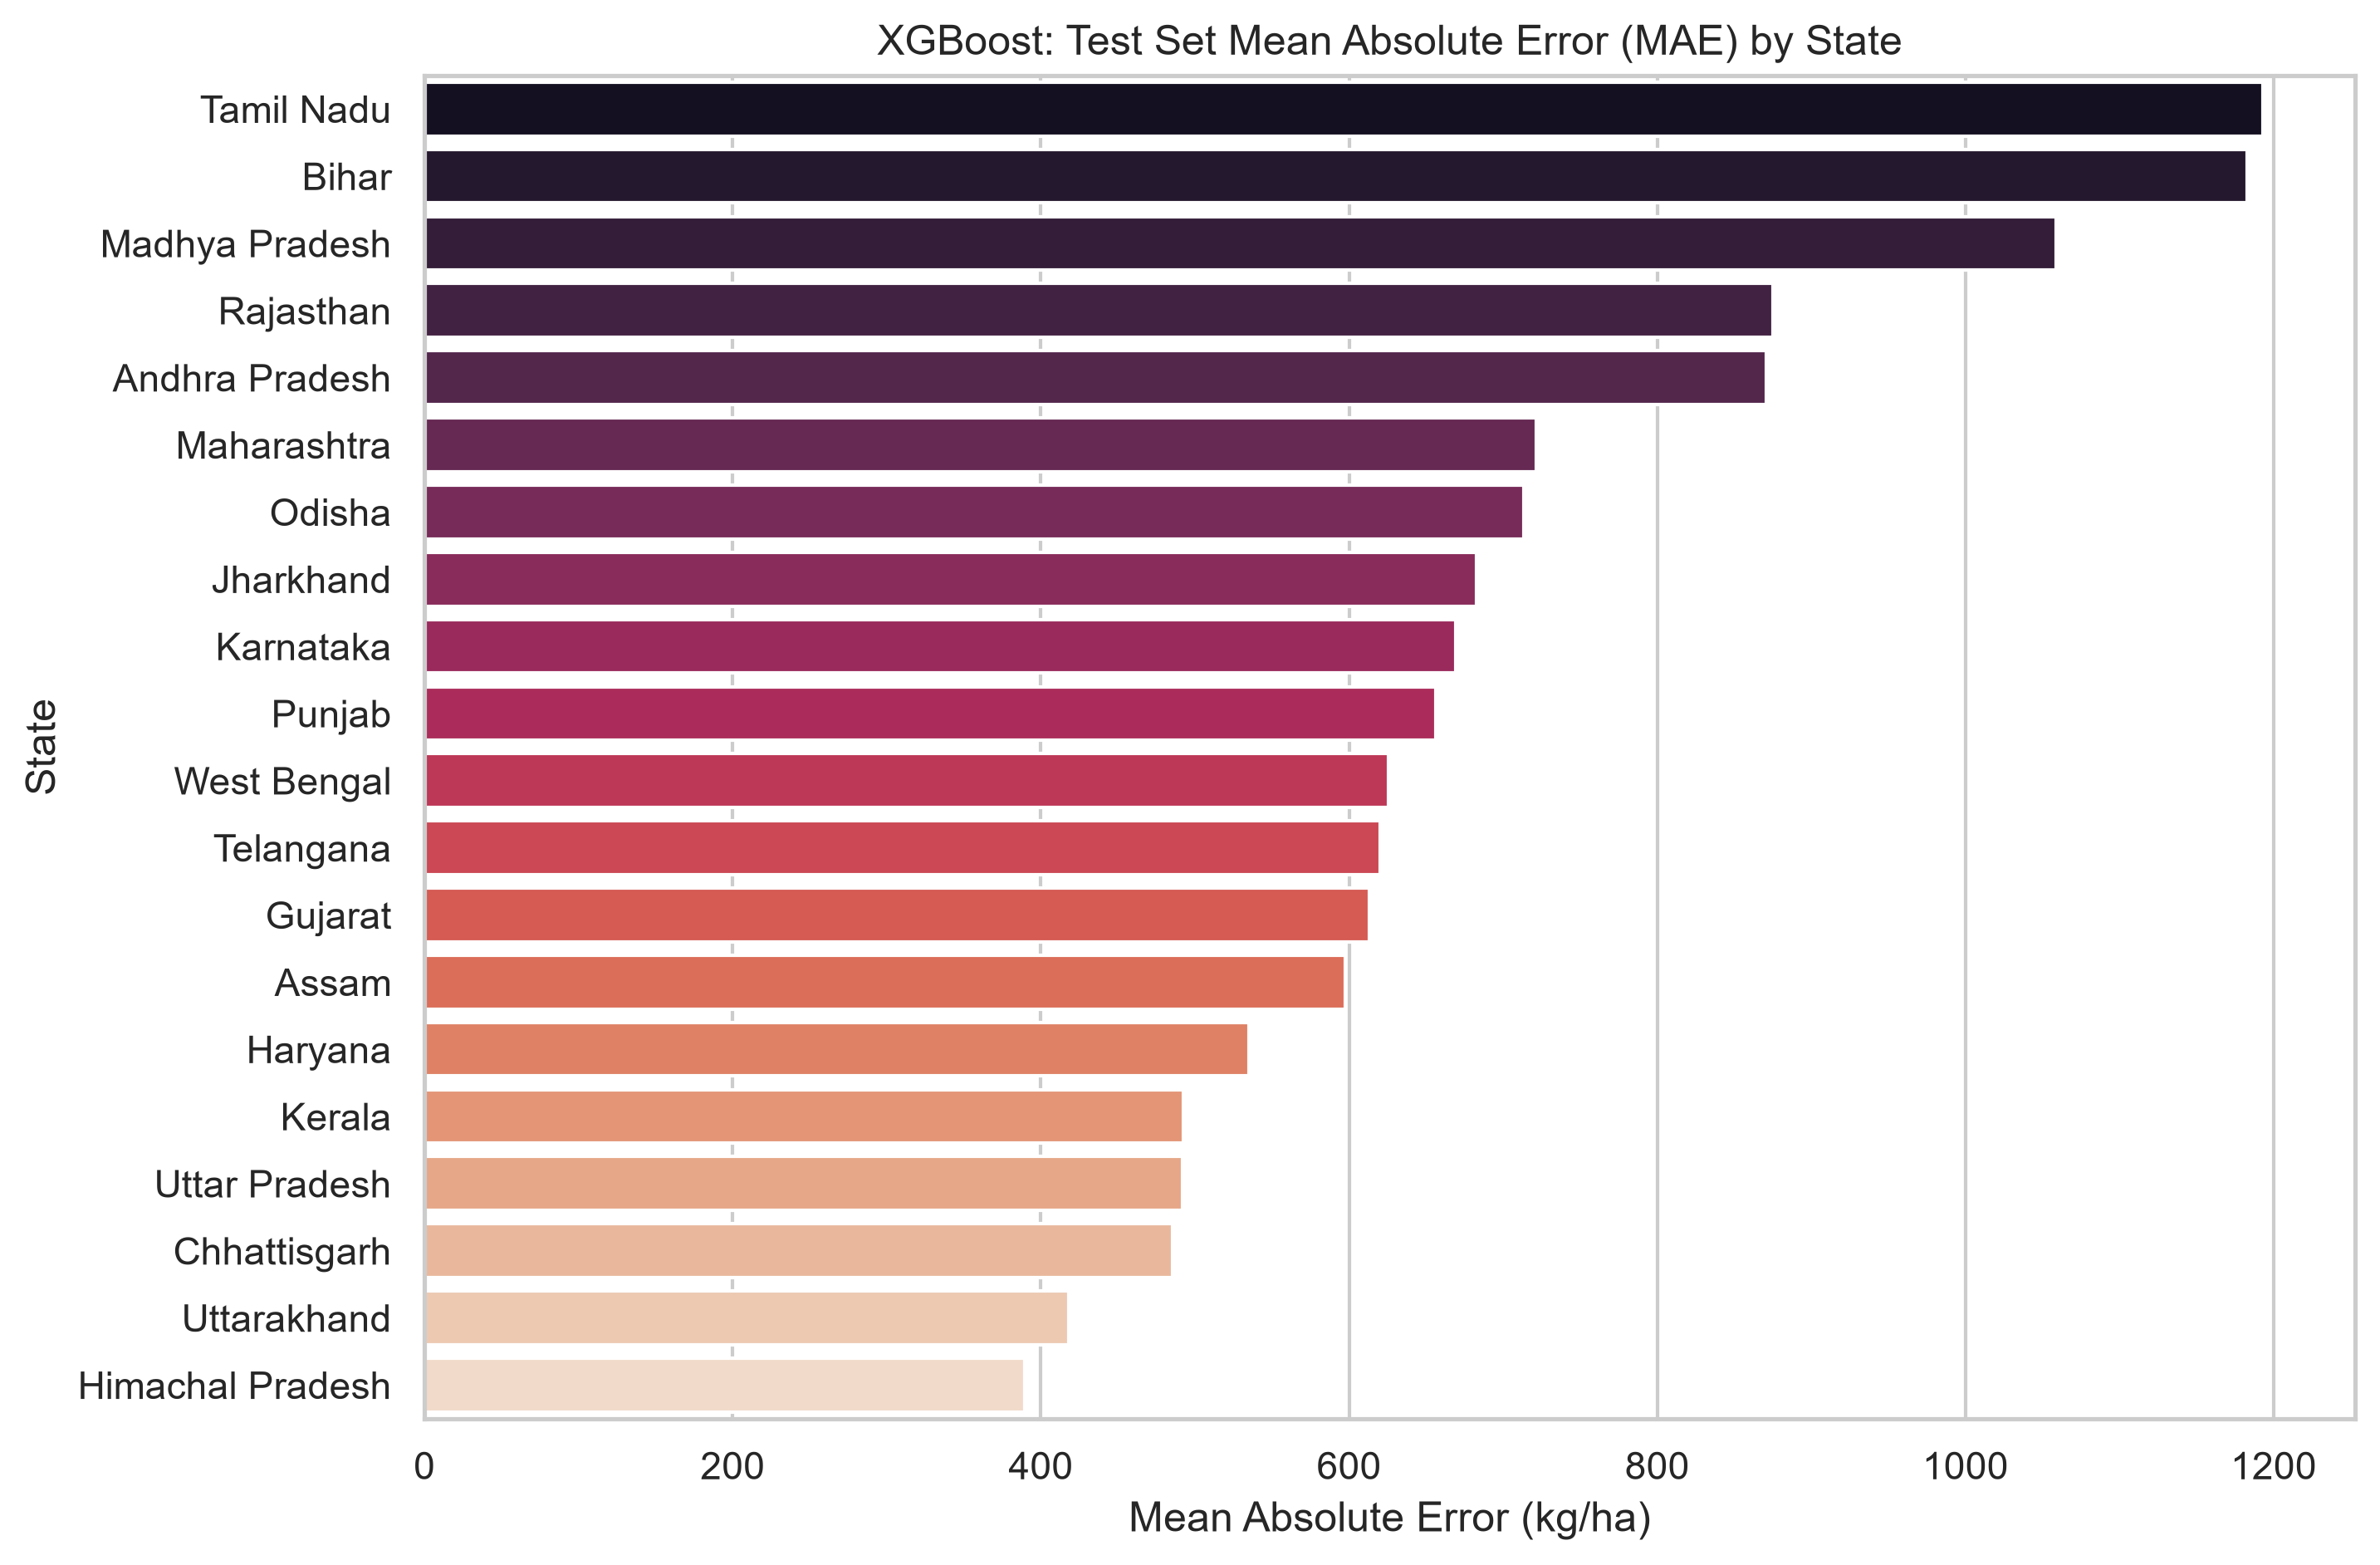

In [8]:
fig_dir = Path('results/figures')
plot_actual_vs_predicted(xgb_test_pred_df, 'XGBoost', fig_dir / 'actual_vs_predicted.png')
plot_residual_distribution(xgb_test_pred_df, 'XGBoost', fig_dir / 'residual_distribution.png')
plot_state_mae(state_metrics, 'XGBoost', fig_dir / 'state_mae_comparison.png')
plot_district_mae_distribution(district_metrics, 'XGBoost', fig_dir / 'district_mae_distribution.png')
print('Evaluation plots saved.')

display(Image(filename='results/figures/actual_vs_predicted.png'))
display(Image(filename='results/figures/residual_distribution.png'))
display(Image(filename='results/figures/state_mae_comparison.png'))